<a href="https://colab.research.google.com/github/Aakanksha-sengar/Marketing-Data-Analysis/blob/main/notebook/ShopEase_Marketing_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ShopEase Marketing Data Analysis

**Goal:** find out which marketing channels, regions and months perform best for a retail e-commerce company (ShopEase), and whether the differences are large enough to act on.

**Questions**
1. Which channel generates the most revenue, and which gives the best return on ad spend (ROAS)?
2. How do regions and months compare?
3. Does spending more on ads go together with more revenue?

**Dataset:** `Marketing Data Analysis.csv` from the [YBI Foundation project datasets](https://github.com/YBIFoundation/ProjectDataSet): 1,000 campaign records for 2025 with channel, region, ad spend, impressions, clicks, conversions and revenue. The dataset does not state a currency, so no currency symbol is used in this notebook.

**Key terms**
- **ROAS** = Revenue / Ad Spend
- **Cost per conversion** = Ad Spend / Conversions
- **Campaign** = one row of the dataset

## 1. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

os.makedirs("output", exist_ok=True)      # charts and the Excel summary are saved here

BLUE, INK, MUTED, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#e5e5e3"
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 110,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
print("Setup complete")

Setup complete


## 2. Load the data

In [2]:
URL = "https://github.com/YBIFoundation/ProjectDataSet/raw/main/Marketing%20Data%20Analysis.csv"
try:
    df = pd.read_csv(URL, index_col=0)                          # works in Colab
except Exception:
    df = pd.read_csv("Marketing Data Analysis.csv", index_col=0)  # local copy, if offline

df["Date"] = pd.to_datetime(df["Date"])
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (1000, 10)


,Date,Channel,Region,Ad_Spend,Impressions,Clicks,Conversions,Revenue,CTR,Conversion_Rate
0,2025-01-01,Facebook,East,35072,324422,12194,1177,487278,4,10
1,2025-01-01,YouTube,North,15612,434523,5654,2927,2517220,1,52
2,2025-01-01,Instagram,East,5582,65898,9991,761,318859,15,8
3,2025-01-02,YouTube,East,21320,105984,7077,2505,2367225,7,35
4,2025-01-04,YouTube,South,10838,298801,16150,2179,1717052,5,13


## 3. Data checks

In [3]:
numeric_cols = ["Ad_Spend", "Impressions", "Clicks", "Conversions", "Revenue"]

checks = pd.DataFrame({
    "Check": ["Missing values", "Duplicate rows", "Zero or negative values in numeric columns",
              "Date range", "Channels", "Regions"],
    "Result": [str(int(df.isna().sum().sum())), str(int(df.duplicated().sum())),
               str(int((df[numeric_cols] <= 0).sum().sum())),
               f"{df['Date'].min().date()} to {df['Date'].max().date()}",
               ", ".join(sorted(df["Channel"].unique())), ", ".join(sorted(df["Region"].unique()))],
})
checks

,Check,Result
0,Missing values,0
1,Duplicate rows,0
2,Zero or negative values in numeric columns,0
3,Date range,2025-01-01 to 2025-12-31
4,Channels,"Email, Facebook, Google Ads, Instagram, YouTube"
5,Regions,"East, North, South, West"


### Are the funnel numbers possible?
Clicks cannot exceed impressions and conversions cannot exceed clicks, so CTR and conversion rate can never be above 100%. The dataset has already stored CTR and Conversion_Rate, so we check whether they hold up.

In [4]:
calc_ctr = df["Clicks"] / df["Impressions"] * 100
calc_cr = df["Conversions"] / df["Clicks"] * 100

clicks_gt_impr = df["Clicks"] > df["Impressions"]
conv_gt_clicks = df["Conversions"] > df["Clicks"]
df["Funnel_Issue"] = clicks_gt_impr | conv_gt_clicks

funnel = pd.DataFrame({
    "Check": ["Clicks > Impressions (CTR above 100%)",
              "Conversions > Clicks (conversion rate above 100%)",
              "Rows with at least one impossible value",
              "Stored CTR equals Clicks / Impressions (rounded)",
              "Stored Conversion_Rate equals Conversions / Clicks (rounded)"],
    "Result": [f"{clicks_gt_impr.sum()} rows",
               f"{conv_gt_clicks.sum()} rows",
               f"{df['Funnel_Issue'].sum()} rows ({df['Funnel_Issue'].mean():.1%})",
               f"{(calc_ctr.round() == df['CTR']).mean():.0%}",
               f"{(calc_cr.round() == df['Conversion_Rate']).mean():.0%}"],
})
funnel

,Check,Result
0,Clicks > Impressions (CTR above 100%),6 rows
1,Conversions > Clicks (conversion rate above 100%),53 rows
2,Rows with at least one impossible value,59 rows (5.9%)
3,Stored CTR equals Clicks / Impressions (rounded),100%
4,Stored Conversion_Rate equals Conversions / Cl...,100%


**Decision:** the stored CTR and Conversion_Rate are just rounded versions of the same impossible values, so they are **not used** for conclusions. The analysis below relies on **ad spend, revenue and conversions**, which have no missing, zero or negative values. The flagged rows are kept (their revenue and spend are valid) and are listed as a data-quality issue.

## 4. Prepare metrics

In [5]:
df["Month_Num"] = df["Date"].dt.month
df["Month"] = df["Date"].dt.strftime("%b")
df["ROAS"] = df["Revenue"] / df["Ad_Spend"]


def summarize(by):
    """Total and per-campaign metrics for a grouping column."""
    g = df.groupby(by).agg(
        Campaigns=("Revenue", "size"),
        Revenue=("Revenue", "sum"),
        Ad_Spend=("Ad_Spend", "sum"),
        Conversions=("Conversions", "sum"),
    )
    g["ROAS"] = g["Revenue"] / g["Ad_Spend"]                      # total revenue / total spend
    g["Cost per Conversion"] = g["Ad_Spend"] / g["Conversions"]
    g["Avg Revenue per Campaign"] = g["Revenue"] / g["Campaigns"]
    return g


print(f"Campaign records : {len(df):,}")
print(f"Total revenue    : {df['Revenue'].sum() / 1e6:,.1f} million")
print(f"Total ad spend   : {df['Ad_Spend'].sum() / 1e6:,.1f} million")
print(f"Overall ROAS     : {df['Revenue'].sum() / df['Ad_Spend'].sum():.1f}x")
print(f"Total conversions: {df['Conversions'].sum():,}")

Campaign records : 1,000
Total revenue    : 916.6 million
Total ad spend   : 27.4 million
Overall ROAS     : 33.5x
Total conversions: 1,520,087


In [6]:
# One fixed colour per channel, used in every channel chart
CHANNEL_ORDER = df.groupby("Channel")["Revenue"].sum().sort_values(ascending=False).index.tolist()
CHANNEL_COLORS = dict(zip(CHANNEL_ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))


def hbar(ax, values, colors, title, fmt):
    """Horizontal bar with the value written next to each bar."""
    y = np.arange(len(values))[::-1]
    ax.barh(y, values.values, color=colors)
    ax.set_yticks(y)
    ax.set_yticklabels(values.index)
    for yi, v in zip(y, values.values):
        ax.text(v + values.max() * 0.01, yi, fmt(v), va="center", color=INK, fontsize=9)
    ax.set_xlim(0, values.max() * 1.2)
    ax.grid(axis="y", visible=False)
    ax.set_title(title)

## 5. Channel analysis
Totals depend on how many campaigns a channel ran, so the table and charts also show **average revenue per campaign**, ROAS and cost per conversion.

In [7]:
channel = summarize("Channel").loc[CHANNEL_ORDER]
channel.round(2)

,Campaigns,Revenue,Ad_Spend,Conversions,ROAS,Cost per Conversion,Avg Revenue per Campaign
Channel,,,,,,,
Email,210,203807018,5751108,327658,35.44,17.55,970509.61
Google Ads,189,188713791,5015347,308477,37.63,16.26,998485.67
Facebook,207,187586332,5559037,307294,33.74,18.09,906214.16
YouTube,201,173481734,5526441,290900,31.39,19.00,863093.20
Instagram,193,162974026,5521429,285758,29.52,19.32,844425.01


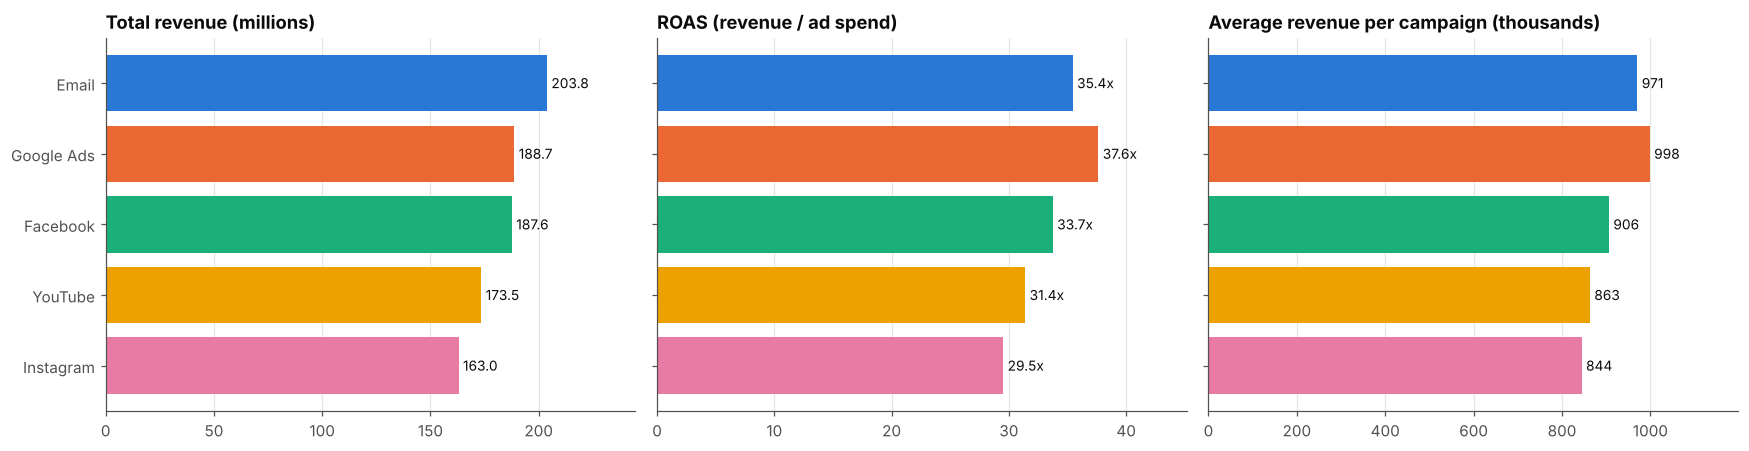

In [8]:
cols = [CHANNEL_COLORS[c] for c in channel.index]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
hbar(axes[0], channel["Revenue"] / 1e6, cols, "Total revenue (millions)", lambda v: f"{v:,.1f}")
hbar(axes[1], channel["ROAS"], cols, "ROAS (revenue / ad spend)", lambda v: f"{v:.1f}x")
hbar(axes[2], channel["Avg Revenue per Campaign"] / 1e3, cols, "Average revenue per campaign (thousands)",
     lambda v: f"{v:,.0f}")
plt.tight_layout()
plt.savefig("output/channel_performance.png", dpi=150, bbox_inches="tight")
plt.show()

### Are the channel differences real?
With 1,000 rows, small differences can be random noise. A **Kruskal-Wallis test** (a test for whether several groups differ, without assuming a normal distribution) is used for the revenue per campaign and the ROAS of each campaign. A p-value below 0.05 is usually taken as evidence of a real difference.

In [9]:
def kruskal_p(column, by):
    groups = [g[column].values for _, g in df.groupby(by)]
    return stats.kruskal(*groups).pvalue


tests = pd.DataFrame({
    "Revenue per campaign (p-value)": [kruskal_p("Revenue", b) for b in ["Channel", "Region", "Month"]],
    "ROAS per campaign (p-value)": [kruskal_p("ROAS", b) for b in ["Channel", "Region", "Month"]],
}, index=["Channel", "Region", "Month"]).round(3)
tests

,Revenue per campaign (p-value),ROAS per campaign (p-value)
Channel,0.048,0.024
Region,0.847,0.404
Month,0.697,0.869


## 6. Region analysis

In [10]:
region = summarize("Region").sort_values("Revenue", ascending=False)
region.round(2)

,Campaigns,Revenue,Ad_Spend,Conversions,ROAS,Cost per Conversion,Avg Revenue per Campaign
Region,,,,,,,
East,275,263871263,7669327,423942,34.41,18.09,959531.87
West,251,221914505,6540265,386364,33.93,16.93,884121.53
South,239,217101083,6538146,366848,33.21,17.82,908372.73
North,235,213676050,6625624,342933,32.25,19.32,909259.79


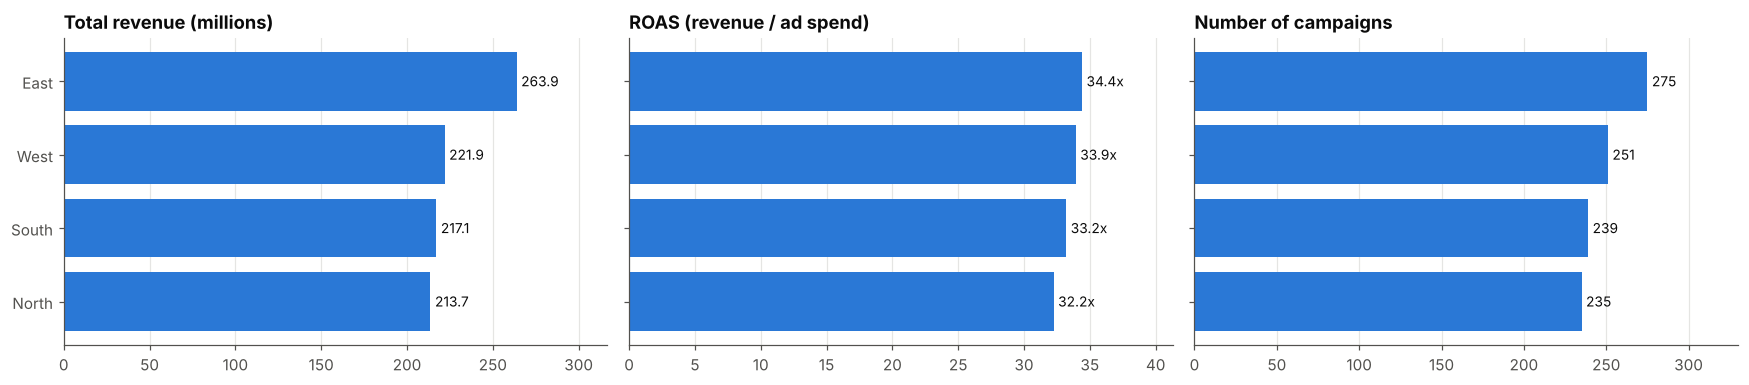

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6), sharey=True)
hbar(axes[0], region["Revenue"] / 1e6, BLUE, "Total revenue (millions)", lambda v: f"{v:,.1f}")
hbar(axes[1], region["ROAS"], BLUE, "ROAS (revenue / ad spend)", lambda v: f"{v:.1f}x")
hbar(axes[2], region["Campaigns"], BLUE, "Number of campaigns", lambda v: f"{v:,.0f}")
plt.tight_layout()
plt.savefig("output/region_performance.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Monthly trend
Revenue is shown next to the **number of campaigns** run each month, and the change in conversions compared with the previous month.

In [12]:
monthly = summarize("Month").loc[MONTHS]
monthly["Conversions change vs previous month (%)"] = monthly["Conversions"].pct_change() * 100
monthly.round(2)

,Campaigns,Revenue,Ad_Spend,Conversions,ROAS,Cost per Conversion,Avg Revenue per Campaign,Conversions change vs previous month (%)
Month,,,,,,,,
Jan,74,74323582,2154817,121509,34.49,17.73,1004372.73,NaN
Feb,76,71637926,2176560,123460,32.91,17.63,942604.29,1.61
Mar,87,70932146,2446349,127037,29.00,19.26,815312.02,2.90
Apr,85,83431965,2525415,126557,33.04,19.95,981552.53,-0.38
May,85,74129683,2282405,125330,32.48,18.21,872113.92,-0.97
Jun,88,81856314,2356237,141115,34.74,16.70,930185.39,12.59
Jul,98,88303685,2729558,142137,32.35,19.20,901058.01,0.72
Aug,92,84900506,2473328,139391,34.33,17.74,922831.59,-1.93
Sep,77,73104838,2106982,115175,34.70,18.29,949413.48,-17.37


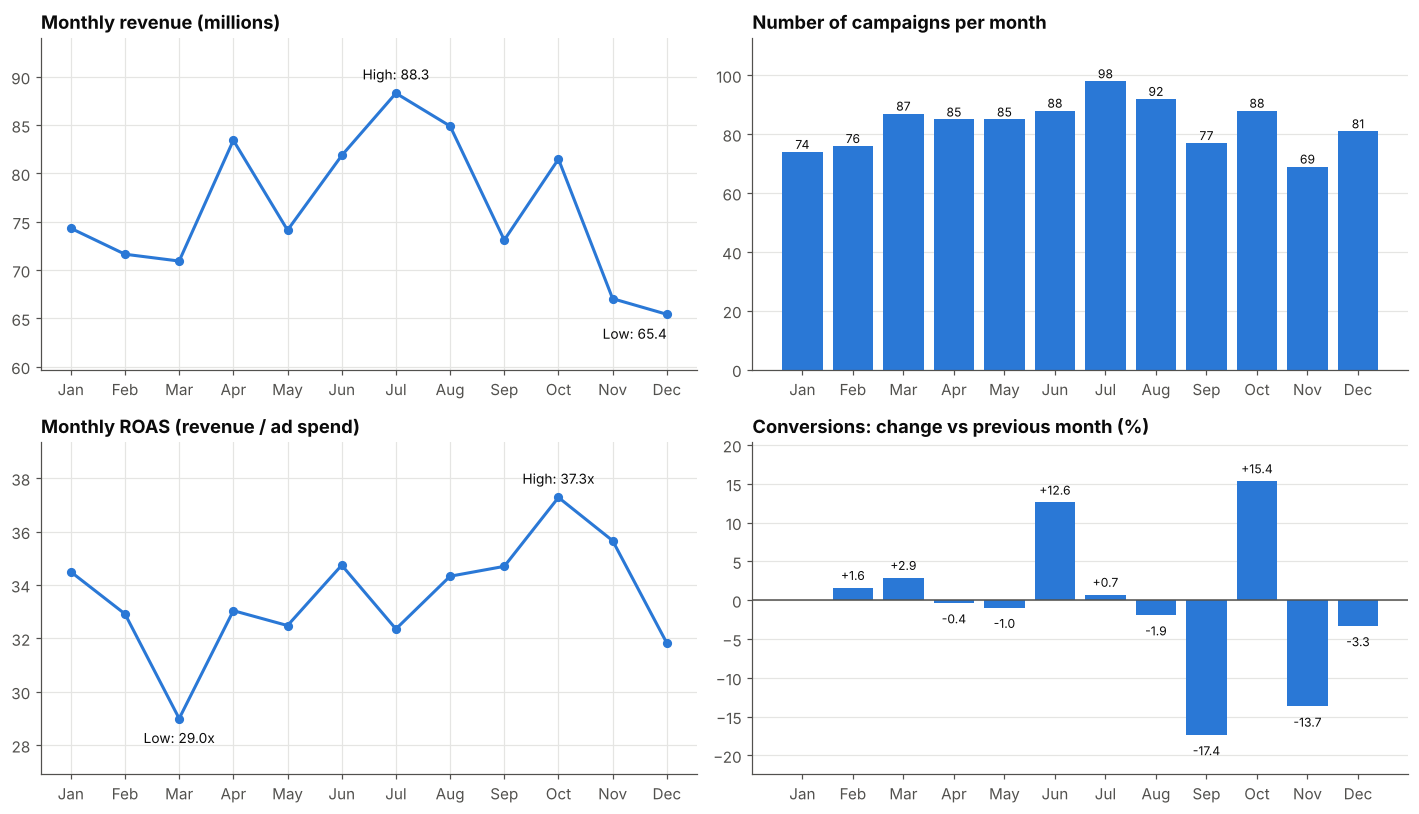

Conversions, second half vs first half of the year: -1.3%


In [13]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
x = np.arange(12)


def line(ax, y, title, fmt):
    ax.plot(x, y.values, color=BLUE, lw=2, marker="o", ms=5)
    ax.set_xticks(x)
    ax.set_xticklabels(MONTHS)
    ax.set_title(title)
    hi, lo = y.values.argmax(), y.values.argmin()
    ax.annotate(f"High: {fmt(y.values[hi])}", (hi, y.values[hi]), xytext=(0, 9),
                textcoords="offset points", ha="center", fontsize=9)
    ax.annotate(f"Low: {fmt(y.values[lo])}", (lo, y.values[lo]), xytext=(0, -16),
                textcoords="offset points", ha="right" if lo == 11 else "center", fontsize=9)
    pad = (y.max() - y.min()) * 0.25
    ax.set_ylim(y.min() - pad, y.max() + pad)


line(axes[0, 0], monthly["Revenue"] / 1e6, "Monthly revenue (millions)", lambda v: f"{v:,.1f}")
axes[0, 1].bar(x, monthly["Campaigns"].values, color=BLUE)
axes[0, 1].set_xticks(x)
axes[0, 1].set_xticklabels(MONTHS)
axes[0, 1].set_title("Number of campaigns per month")
for xi, v in zip(x, monthly["Campaigns"].values):
    axes[0, 1].text(xi, v + 1, str(v), ha="center", fontsize=8, color=INK)
axes[0, 1].set_ylim(0, monthly["Campaigns"].max() * 1.15)
axes[0, 1].grid(axis="x", visible=False)
line(axes[1, 0], monthly["ROAS"], "Monthly ROAS (revenue / ad spend)", lambda v: f"{v:.1f}x")

growth = monthly["Conversions change vs previous month (%)"].fillna(0)
axes[1, 1].bar(x, growth.values, color=BLUE)
axes[1, 1].axhline(0, color=MUTED, lw=1)
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(MONTHS)
axes[1, 1].set_title("Conversions: change vs previous month (%)")
for xi, v in zip(x[1:], growth.values[1:]):
    axes[1, 1].text(xi, v + (1 if v >= 0 else -2.6), f"{v:+.1f}", ha="center", fontsize=8, color=INK)
axes[1, 1].set_ylim(growth.min() - 5, growth.max() + 5)
axes[1, 1].grid(axis="x", visible=False)

plt.tight_layout()
plt.savefig("output/monthly_trends.png", dpi=150, bbox_inches="tight")
plt.show()

h1 = monthly["Conversions"].iloc[:6].sum()
h2 = monthly["Conversions"].iloc[6:].sum()
print(f"Conversions, second half vs first half of the year: {h2 / h1 - 1:+.1%}")

## 8. Does more ad spend mean more revenue?

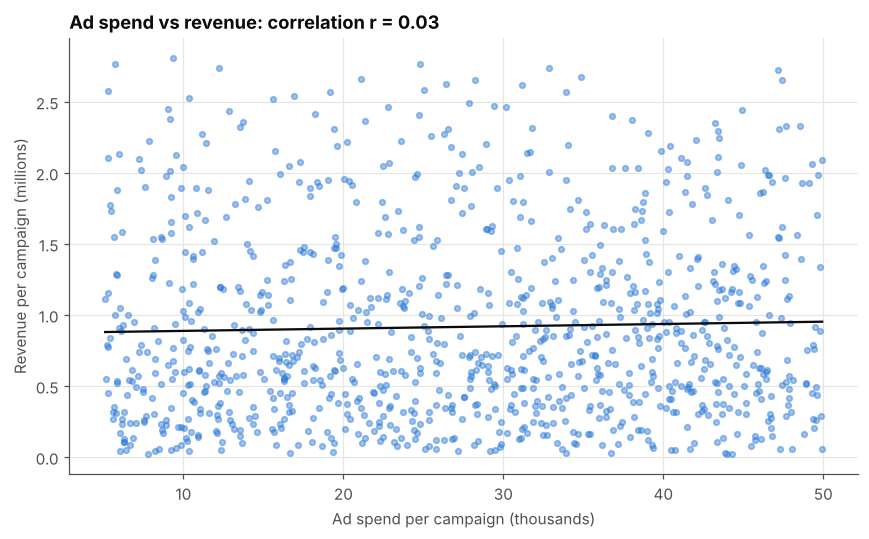

Ad spend vs revenue : r = 0.032 (p = 0.318)
Conversions vs revenue: r = 0.792


In [14]:
r, p = stats.pearsonr(df["Ad_Spend"], df["Revenue"])
r_conv, _ = stats.pearsonr(df["Conversions"], df["Revenue"])

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df["Ad_Spend"] / 1e3, df["Revenue"] / 1e6, s=14, alpha=0.45, color=BLUE)
slope, intercept = np.polyfit(df["Ad_Spend"], df["Revenue"], 1)
xs = np.linspace(df["Ad_Spend"].min(), df["Ad_Spend"].max(), 50)
ax.plot(xs / 1e3, (slope * xs + intercept) / 1e6, color=INK, lw=1.5)
ax.set_xlabel("Ad spend per campaign (thousands)")
ax.set_ylabel("Revenue per campaign (millions)")
ax.set_title(f"Ad spend vs revenue: correlation r = {r:.2f}")
plt.tight_layout()
plt.savefig("output/spend_vs_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Ad spend vs revenue : r = {r:.3f} (p = {p:.3f})")
print(f"Conversions vs revenue: r = {r_conv:.3f}")

A correlation near 0 means that campaigns with a bigger budget did **not** earn noticeably more revenue in this data, while revenue follows conversions closely. Because spend barely explains revenue, ROAS should be read with care.

## 9. Region x channel

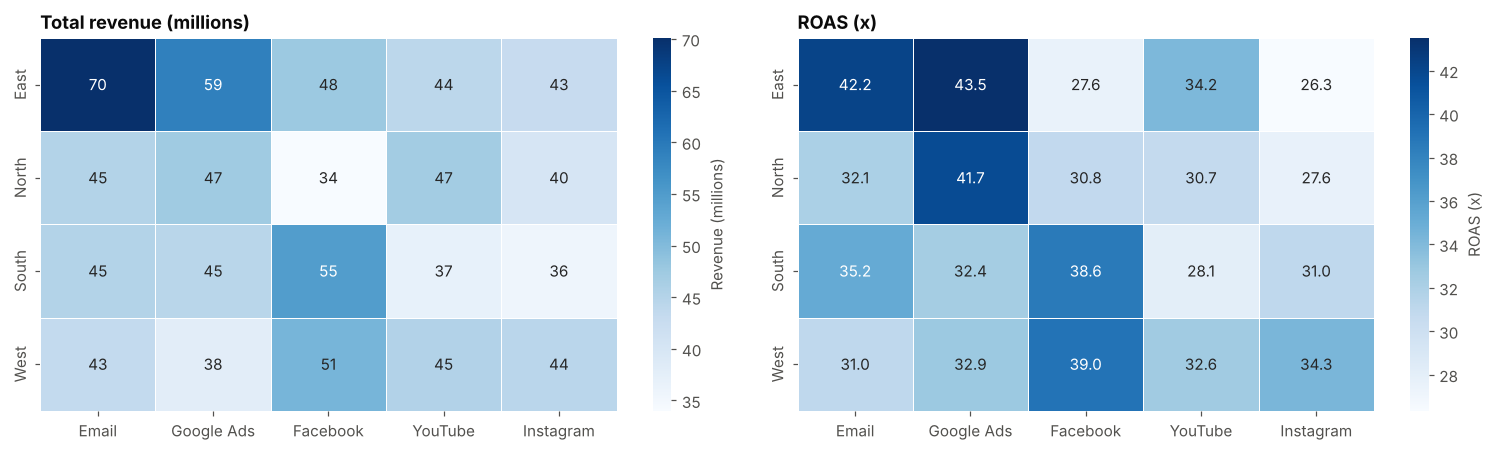

In [15]:
rev_pivot = df.pivot_table(index="Region", columns="Channel", values="Revenue", aggfunc="sum")[CHANNEL_ORDER] / 1e6
roas_pivot = (df.pivot_table(index="Region", columns="Channel", values="Revenue", aggfunc="sum")
              / df.pivot_table(index="Region", columns="Channel", values="Ad_Spend", aggfunc="sum"))[CHANNEL_ORDER]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
sns.heatmap(rev_pivot, annot=True, fmt=".0f", cmap="Blues", linewidths=0.5, linecolor="white",
            cbar_kws={"label": "Revenue (millions)"}, ax=axes[0])
axes[0].set_title("Total revenue (millions)")
sns.heatmap(roas_pivot, annot=True, fmt=".1f", cmap="Blues", linewidths=0.5, linecolor="white",
            cbar_kws={"label": "ROAS (x)"}, ax=axes[1])
axes[1].set_title("ROAS (x)")
for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.grid(False)
plt.tight_layout()
plt.savefig("output/region_channel_heatmaps.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Insights and recommendations

**Insights**
- **Overall:** 1,000 campaigns generated about 916.6 million in revenue from 27.4 million of ad spend, an overall ROAS of 33.5x.
- **Channels:** Email has the highest total revenue (203.8 million), but it also ran the most campaigns (210). **Google Ads** earns the most per campaign (about 998 thousand), has the best ROAS (37.6x) and the lowest cost per conversion (16.3). **Instagram** is the weakest (ROAS 29.5x, cost per conversion 19.3). The channel differences are borderline significant (p = 0.048 for revenue per campaign, p = 0.024 for ROAS).
- **Regions:** East has the highest total revenue (263.9 million), mainly because it ran the most campaigns (275). Regions do **not** differ significantly (p = 0.85 for revenue, p = 0.40 for ROAS).
- **Months:** July has the highest revenue (88.3 million) and also the most campaigns (98). October has the best ROAS (37.3x). Months do not differ significantly (p = 0.70). Conversions in the second half of the year were only about 1% lower than in the first half (-1.3%), so there is no clear seasonal trend.
- **Spend vs revenue:** correlation is only 0.03, so bigger budgets did not go with higher revenue in this data. Revenue follows conversions (r = 0.79).
- **Data quality:** 59 rows (5.9%) have impossible click or conversion numbers.

**Recommendations**
1. Prioritise **Google Ads** and **Email**, and review **Instagram** and **YouTube**, which have the lowest ROAS and the highest cost per conversion.
2. Do not move budget between regions or months based on this data alone, because those differences are not significant. Compare average revenue per campaign, not totals.
3. Test budget changes in a controlled way before scaling, since spend and revenue are not related here.
4. Fix tracking for impressions, clicks and conversions so that funnel rates can be trusted.

## 11. Export a summary to Excel

In [16]:
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

path = "output/shopease_summary.xlsx"
with pd.ExcelWriter(path, engine="openpyxl") as writer:
    channel.round(2).reset_index().to_excel(writer, sheet_name="Channel", index=False)
    region.round(2).reset_index().to_excel(writer, sheet_name="Region", index=False)
    monthly.round(2).reset_index().to_excel(writer, sheet_name="Month", index=False)
    rev_pivot.round(1).reset_index().to_excel(writer, sheet_name="Region x Channel Revenue", index=False)
    funnel.to_excel(writer, sheet_name="Data Checks", index=False)

    for ws in writer.book.worksheets:
        for cell in ws[1]:
            cell.font = Font(bold=True, color="FFFFFF")
            cell.fill = PatternFill("solid", fgColor="2A78D6")
            cell.alignment = Alignment(horizontal="center", wrap_text=True)
        ws.freeze_panes = "A2"
        for i, col_cells in enumerate(ws.columns, start=1):
            width = max(len(str(c.value)) if c.value is not None else 0 for c in col_cells)
            ws.column_dimensions[get_column_letter(i)].width = min(max(width + 3, 12), 50)
        for row in ws.iter_rows(min_row=2):
            for c in row:
                if isinstance(c.value, float):
                    c.number_format = "#,##0.00"
                elif isinstance(c.value, int) and c.value > 999:
                    c.number_format = "#,##0"

print("Saved:", path)
print("Files in output/:", sorted(os.listdir("output")))

Saved: output/shopease_summary.xlsx
Files in output/: ['channel_performance.png', 'monthly_trends.png', 'region_channel_heatmaps.png', 'region_performance.png', 'shopease_summary.xlsx', 'spend_vs_revenue.png']


## 12. Limitations
- This looks like a **sample dataset**: a ROAS above 30x is far higher than typical real campaigns, and impressions, clicks and spend are unrelated to each other. Treat the results as a practice analysis, not as real business advice.
- No currency or profit is given. ROAS measures revenue per unit of ad spend, not profit.
- Six comparisons were tested. A p-value close to 0.05 is weak evidence, so the channel result should be confirmed with more data.
- The data covers one year and each row is one campaign, so seasonality cannot be separated from the number of campaigns run.